# **💳 Credit Card Fraud Detection: ML Models 2026**

**What this notebook covers (beginner friendly):**
1. Load & understand the data
2. Quick EDA (fraud rate, amount, hour, channel)
3. Clean data & remove *leaky* columns
4. Train 5 models: Logistic Regression → Decision Tree → Random Forest → XGBoost → LightGBM
5. Compare with the right metrics for imbalanced data (ROC-AUC, PR-AUC, F1)
6. Tune the decision threshold, check feature importance, conclude



## **1. Import libraries**

In [1]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
import warnings; warnings.filterwarnings("ignore")

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from sklearn.metrics import (roc_auc_score, average_precision_score, f1_score, precision_score,
                             recall_score, accuracy_score, confusion_matrix, precision_recall_curve)
sns.set_style("whitegrid"); RANDOM_STATE = 42

## **2. Load the data**

In [2]:
# On Kaggle, change the path to your dataset path (see the right-side 'Input' panel)
PATH = "/kaggle/input/datasets/mohankrishnathalla/credit-card-fraud-detection-dataset-2026/credit_card_fraud_detection_2026.csv"
import os
if not os.path.exists(PATH): PATH = "credit_card_fraud_detection_2026.csv"
df = pd.read_csv(PATH)
print("Shape:", df.shape)
df.head()

Shape: (100000, 43)


,transaction_id,customer_id,card_id,merchant_id,transaction_datetime,transaction_amount,merchant_category,merchant_country,transaction_hour,transaction_day_of_week,...,browser,is_weekend,avg_transaction_amount_30d,std_transaction_amount_30d,num_declined_last_30d,num_chargebacks_ever,email_domain,is_fraud,fraud_type,fraud_amount_lost
0,TXN-00000001,CUS-00006042,CRD-00006042,MER-00002507,2026-01-01 02:28:51,37.36,Healthcare & Pharmacy,USA,2,Monday,...,Chrome,0,93.91,39.48,0,0,corporate,0,Legitimate,0.0
1,TXN-00000002,CUS-00005262,CRD-00005262,MER-00000189,2026-01-01 03:15:18,50.04,Restaurant & Dining,Germany,3,Monday,...,NaN,0,180.05,134.45,0,0,yahoo,0,Legitimate,0.0
2,TXN-00000003,CUS-00005901,CRD-00005901,MER-00002054,2026-01-01 03:44:38,38.87,Grocery & Supermarket,Australia,3,Monday,...,Chrome,0,42.00,22.46,0,0,hotmail,0,Legitimate,0.0
3,TXN-00000004,CUS-00006958,CRD-00006958,MER-00000310,2026-01-01 03:53:41,46.60,Gas Station,China,3,Monday,...,NaN,0,64.87,29.76,0,0,gmail,0,Legitimate,0.0
4,TXN-00000005,CUS-00003543,CRD-00003543,MER-00001197,2026-01-01 04:29:08,62.13,Clothing & Apparel,UK,4,Monday,...,NaN,0,47.19,18.52,0,0,gmail,0,Legitimate,0.0


In [3]:
print("Duplicate rows:", df.duplicated().sum())
print("Missing values:\n", df.isna().sum()[df.isna().sum() > 0])
print("\nFraud rate: {:.2%}".format(df["is_fraud"].mean()))

Duplicate rows: 0
Missing values:
 browser    41709
dtype: int64

Fraud rate: 2.05%


**Notes:** `browser` is empty for in-store/ATM transactions (no browser used), so we will fill it with `"None"`.
The target is **`is_fraud`** (1 = fraud, 0 = legitimate).

## **3. Exploratory Data Analysis (EDA)**

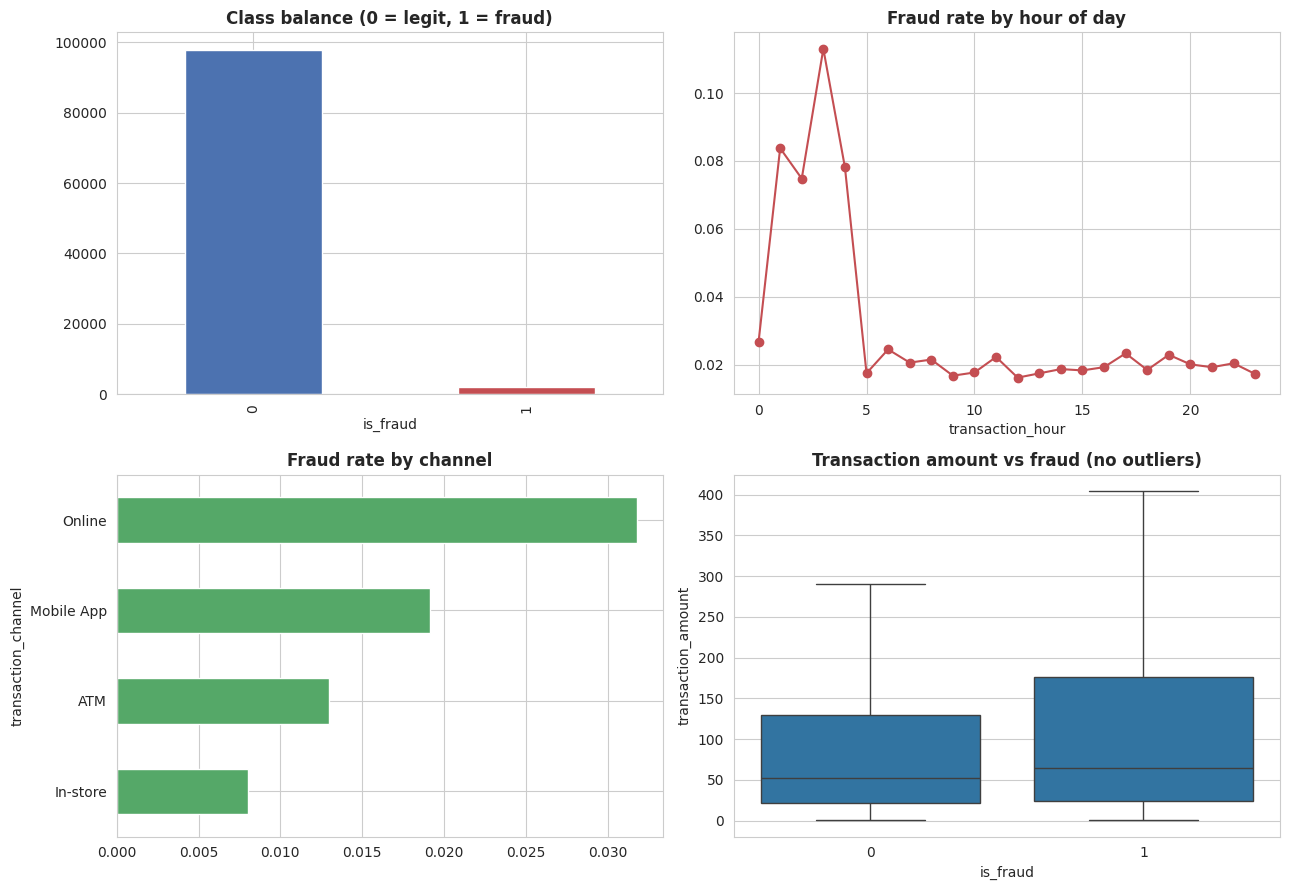

In [4]:
fig, ax = plt.subplots(2, 2, figsize=(13, 9))
df["is_fraud"].value_counts().plot(kind="bar", ax=ax[0,0], color=["#4c72b0","#c44e52"])
ax[0,0].set_title("Class balance (0 = legit, 1 = fraud)",fontweight='bold')

df.groupby("transaction_hour")["is_fraud"].mean().plot(ax=ax[0,1], marker="o", color="#c44e52")
ax[0,1].set_title("Fraud rate by hour of day",fontweight='bold')

df.groupby("transaction_channel")["is_fraud"].mean().sort_values().plot(kind="barh", ax=ax[1,0], color="#55a868")
ax[1,0].set_title("Fraud rate by channel",fontweight='bold')

sns.boxplot(data=df, x="is_fraud", y="transaction_amount", ax=ax[1,1], showfliers=False)
ax[1,1].set_title("Transaction amount vs fraud (no outliers)",fontweight='bold')
plt.tight_layout(); plt.show()

In [5]:
print(df["fraud_type"].value_counts())
top = df.corr(numeric_only=True)["is_fraud"].drop(["is_fraud","fraud_amount_lost"]).abs().sort_values(ascending=False).head(10)
print("\nTop numeric features correlated with fraud:\n", top.round(3))

fraud_type
Legitimate            97945
Card-Not-Present       1054
Account-Takeover        447
Synthetic-Identity      309
Card-Present            245
Name: count, dtype: int64

Top numeric features correlated with fraud:
 high_risk_country            0.144
international_transaction    0.107
distance_from_home_km        0.081
card_present                 0.066
transactions_last_1h         0.064
used_chip                    0.062
num_chargebacks_ever         0.050
used_pin                     0.043
amount_last_1h               0.043
transactions_last_24h        0.034
Name: is_fraud, dtype: float64


## **4. Data cleaning & feature engineering**
- **Drop ID columns** (`transaction_id`, `customer_id`, `card_id`, `merchant_id`): they are unique labels, not patterns.
- **Drop `fraud_type` and `fraud_amount_lost`**: they are only known *after* fraud is found → **data leakage** (the model would cheat).
- **Drop noisy columns** (state, day, month, weekday, gender, weekend): tests showed they add noise, not signal.
- Create new **smart features** (night flag, amount vs limit, amount z-score, travel speed, risk score).
- One-hot encode text columns.

In [6]:
data = df.copy()
data["browser"] = data["browser"].fillna("None")
# --- new features ---
data["is_night"] = data["transaction_hour"].isin([0,1,2,3,4,5]).astype(int)
data["amount_to_limit"] = data["transaction_amount"] / data["credit_limit"]
data["amount_z"] = (data["transaction_amount"] - data["avg_transaction_amount_30d"]) / (data["std_transaction_amount_30d"] + 1)
data["avg_amt_1h"] = data["amount_last_1h"] / (data["transactions_last_1h"] + 1)
data["speed_kmh"] = data["distance_from_last_tx_km"] / (data["days_since_last_transaction"]*24 + 0.1)
data["risk_score"] = (data["high_risk_country"] + data["international_transaction"] + (1-data["card_present"])
                      + (data["num_chargebacks_ever"]>0) + (data["num_declined_last_30d"]>0))

drop_cols = ["transaction_id","customer_id","card_id","merchant_id","transaction_datetime",   # IDs
             "fraud_type","fraud_amount_lost",                                                # leakage
             "customer_state","transaction_day_of_week","customer_gender","is_weekend"]       # noise
y = data["is_fraud"]
X = pd.get_dummies(data.drop(columns=drop_cols + ["is_fraud"]), drop_first=True)
X.columns = X.columns.str.replace(r"[^0-9a-zA-Z_]", "_", regex=True)   # safe names for XGBoost/LightGBM
print("Final feature matrix:", X.shape)

Final feature matrix: (100000, 80)


## **5. Train / Validation / Test split**
70% train, 15% validation (used to pick the threshold), 15% test (final honest score). `stratify` keeps the same fraud rate in every part.

In [7]:
X_tr, X_tmp, y_tr, y_tmp = train_test_split(X, y, test_size=0.30, stratify=y, random_state=RANDOM_STATE)
X_val, X_te, y_val, y_te = train_test_split(X_tmp, y_tmp, test_size=0.50, stratify=y_tmp, random_state=RANDOM_STATE)
print(X_tr.shape, X_val.shape, X_te.shape)
print("Fraud rate -> train {:.2%} | val {:.2%} | test {:.2%}".format(y_tr.mean(), y_val.mean(), y_te.mean()))

(70000, 80) (15000, 80) (15000, 80)
Fraud rate -> train 2.06% | val 2.05% | test 2.05%


## **6. Train multiple models (baseline → best)**
Models go from simple to powerful. We use **shallow, regularized** models so they do not memorise noise, and handle imbalance with class weights (or by tuning the threshold later).

In [8]:
models = {
 "1. Logistic Regression (baseline)": make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000, C=0.1, class_weight="balanced")),
 "2. Decision Tree": DecisionTreeClassifier(max_depth=5, min_samples_leaf=50, class_weight="balanced", random_state=RANDOM_STATE),
 "3. Random Forest": RandomForestClassifier(n_estimators=300, max_depth=8, min_samples_leaf=30, max_features="sqrt",
                                            class_weight="balanced_subsample", n_jobs=-1, random_state=RANDOM_STATE),
 "4. XGBoost": XGBClassifier(n_estimators=400, learning_rate=0.02, max_depth=3, min_child_weight=10, subsample=0.8,
                             colsample_bytree=0.6, reg_lambda=10, eval_metric="aucpr", n_jobs=-1, random_state=RANDOM_STATE),
 "5. LightGBM": LGBMClassifier(n_estimators=400, learning_rate=0.02, num_leaves=4, min_child_samples=100, subsample=0.8,
                               subsample_freq=1, colsample_bytree=0.5, reg_lambda=10, n_jobs=-1, random_state=RANDOM_STATE, verbose=-1),
}
def best_f1_threshold(y_true, p):
    pr, rc, th = precision_recall_curve(y_true, p)
    f = 2*pr*rc/(pr+rc+1e-9)
    i = np.argmax(f[:-1]); return th[i], pr[i], rc[i], f[i]

rows, val_proba = [], {}
for name, m in models.items():
    m.fit(X_tr, y_tr)
    p = m.predict_proba(X_val)[:,1]; val_proba[name] = p
    t, pr_, rc_, f_ = best_f1_threshold(y_val, p)      # fair comparison: each model at its own best threshold
    rows.append({"Model":name, "ROC-AUC":roc_auc_score(y_val,p), "PR-AUC":average_precision_score(y_val,p),
                 "Precision":pr_, "Recall":rc_, "F1":f_})
res = pd.DataFrame(rows).set_index("Model").round(4)
res.sort_values("PR-AUC", ascending=False)

,ROC-AUC,PR-AUC,Precision,Recall,F1
Model,,,,,
5. LightGBM,0.8590,0.1525,0.2074,0.2532,0.2281
4. XGBoost,0.8589,0.1494,0.1996,0.2922,0.2372
3. Random Forest,0.8390,0.1309,0.1604,0.2922,0.2071
1. Logistic Regression (baseline),0.8473,0.1221,0.1365,0.3896,0.2022
2. Decision Tree,0.8091,0.0802,0.1075,0.3636,0.1659


## **7. Compare models**

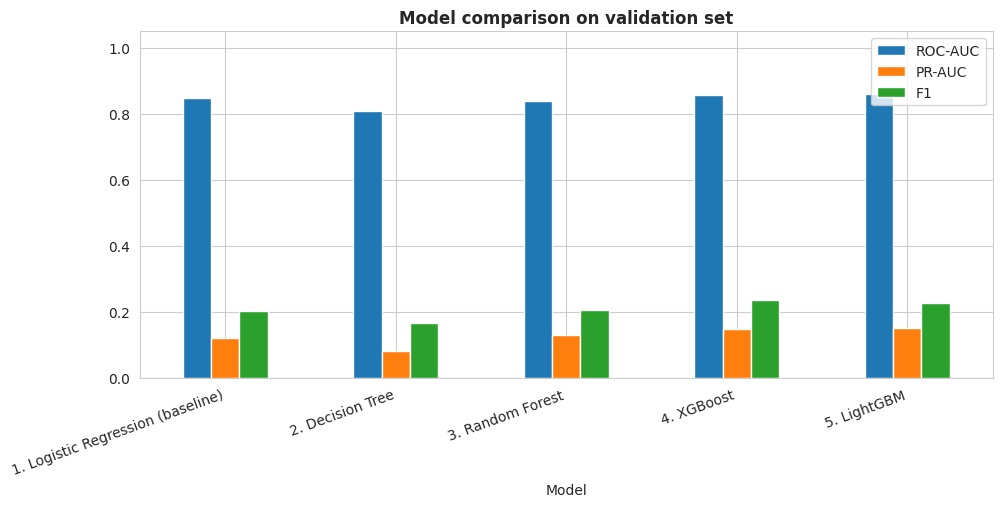

Best model (by PR-AUC): 5. LightGBM


In [9]:
res[["ROC-AUC","PR-AUC","F1"]].plot(kind="bar", figsize=(11,4.5), ylim=(0,1.05))
plt.title("Model comparison on validation set",fontweight='bold'); plt.xticks(rotation=20, ha="right"); plt.show()
best = res["PR-AUC"].idxmax(); print("Best model (by PR-AUC):", best)

## **8. Tune the decision threshold**
By default a transaction is flagged as fraud when probability ≥ 0.5. For rare fraud, a better cut-off often gives a better **F1** (balance of precision & recall). We choose it on the **validation** set only.

Best threshold: 0.118


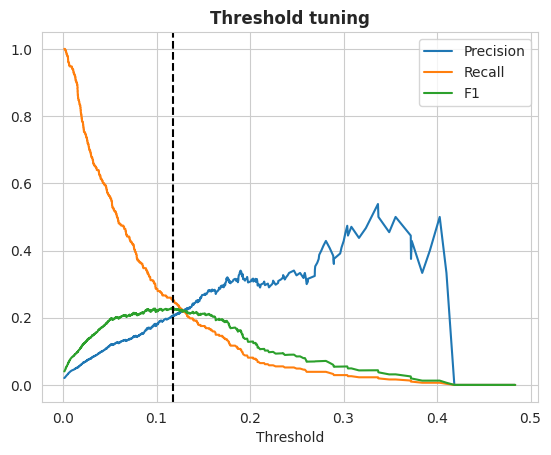

In [10]:
p_val = val_proba[best]
prec, rec, thr = precision_recall_curve(y_val, p_val)
f1s = 2*prec*rec/(prec+rec+1e-9)
best_thr, *_ = best_f1_threshold(y_val, p_val)
print("Best threshold: {:.3f}".format(best_thr))
plt.plot(thr, prec[:-1], label="Precision"); plt.plot(thr, rec[:-1], label="Recall"); plt.plot(thr, f1s[:-1], label="F1")
plt.axvline(best_thr, ls="--", c="k"); plt.legend(); plt.xlabel("Threshold"); plt.title("Threshold tuning",fontweight='bold'); plt.show()

## **9. Final evaluation on the unseen TEST set**

Model      : 5. LightGBM
Accuracy   : 0.9677
ROC-AUC    : 0.8502
PR-AUC     : 0.2081
Precision  : 0.2479
Recall     : 0.2825
F1-score   : 0.2640
Recall in top 5% riskiest transactions: 42.5%  (random would be 5%)


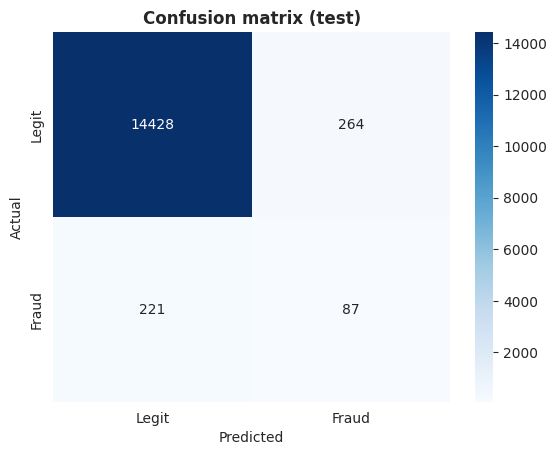

In [11]:
final = models[best]
p_te = final.predict_proba(X_te)[:,1]
pred = (p_te >= best_thr).astype(int)
print(f"Model      : {best}")
print(f"Accuracy   : {accuracy_score(y_te,pred):.4f}")
print(f"ROC-AUC    : {roc_auc_score(y_te,p_te):.4f}")
print(f"PR-AUC     : {average_precision_score(y_te,p_te):.4f}")
print(f"Precision  : {precision_score(y_te,pred):.4f}")
print(f"Recall     : {recall_score(y_te,pred):.4f}")
print(f"F1-score   : {f1_score(y_te,pred):.4f}")
k = int(0.05*len(y_te)); top = np.argsort(-p_te)[:k]
recall_top5 = y_te.values[top].sum()/y_te.sum()
print(f"Recall in top 5% riskiest transactions: {recall_top5:.1%}  (random would be 5%)")
sns.heatmap(confusion_matrix(y_te,pred), annot=True, fmt="d", cmap="Blues",
            xticklabels=["Legit","Fraud"], yticklabels=["Legit","Fraud"])
plt.xlabel("Predicted"); plt.ylabel("Actual"); plt.title("Confusion matrix (test)",fontweight='bold'); plt.show()

## **10. Feature importance (what drives fraud?)**

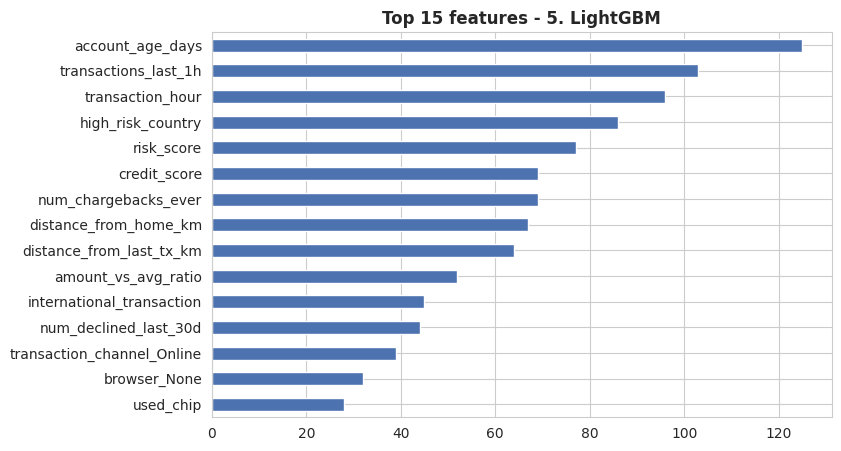

In [12]:
imp = pd.Series(final.feature_importances_, index=X.columns).sort_values().tail(15)
imp.plot(kind="barh", figsize=(8,5), color="#4c72b0"); plt.title(f"Top 15 features - {best}",fontweight='bold'); plt.show()

## **11. Conclusion**

In [13]:
from IPython.display import Markdown
tn, fp, fn, tp = confusion_matrix(y_te, pred).ravel()
Markdown(f'''
- **Best model:** {best} (threshold = {best_thr:.2f}).
- On unseen test data it reached **ROC-AUC {roc_auc_score(y_te,p_te):.3f}**, **PR-AUC {average_precision_score(y_te,p_te):.3f}** and **F1 {f1_score(y_te,pred):.3f}**
  (it caught **{tp} of {tp+fn}** frauds with **{fp}** false alarms).
- If analysts only review the **top 5% riskiest** transactions, they catch **{recall_top5:.0%}** of all fraud (a random review would catch 5%) - about **{recall_top5/0.05:.1f}x lift**.
- Boosting models beat the Logistic Regression baseline, so non-linear patterns matter.
- Accuracy looks high for every model because of the 98/2 imbalance, hence PR-AUC, F1 and recall are the fair scores.
- Fraud in this dataset overlaps heavily with normal behaviour (noisy/synthetic), so scores near ROC-AUC ~0.85 are about the ceiling we found; extra tuning gave little gain.
- **Fixes that mattered:** removing leaky columns, class weights, and threshold tuning.
- **Next steps:** time-based split, SMOTE/under-sampling, Optuna tuning, cost-based threshold (money lost vs. review cost), SHAP explanations.
''')


- **Best model:** 5. LightGBM (threshold = 0.12).
- On unseen test data it reached **ROC-AUC 0.850**, **PR-AUC 0.208** and **F1 0.264**
  (it caught **87 of 308** frauds with **264** false alarms).
- If analysts only review the **top 5% riskiest** transactions, they catch **43%** of all fraud (a random review would catch 5%) - about **8.5x lift**.
- Boosting models beat the Logistic Regression baseline, so non-linear patterns matter.
- Accuracy looks high for every model because of the 98/2 imbalance, hence PR-AUC, F1 and recall are the fair scores.
- Fraud in this dataset overlaps heavily with normal behaviour (noisy/synthetic), so scores near ROC-AUC ~0.85 are about the ceiling we found; extra tuning gave little gain.
- **Fixes that mattered:** removing leaky columns, class weights, and threshold tuning.
- **Next steps:** time-based split, SMOTE/under-sampling, Optuna tuning, cost-based threshold (money lost vs. review cost), SHAP explanations.


*If this notebook helped, please upvote 👍 and share feedback!*